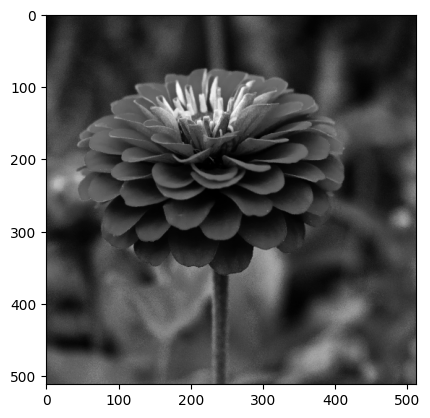

In [1]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

image = cv2.imread('img.jpg', cv2.IMREAD_GRAYSCALE)
h, w = image.shape
s = min(h, w)
image = image[(h - s) // 2:(h + s) // 2, (w - s) // 2:(w + s) // 2]
image = cv2.resize(image, (512, 512))
plt.imshow(image, cmap='gray')


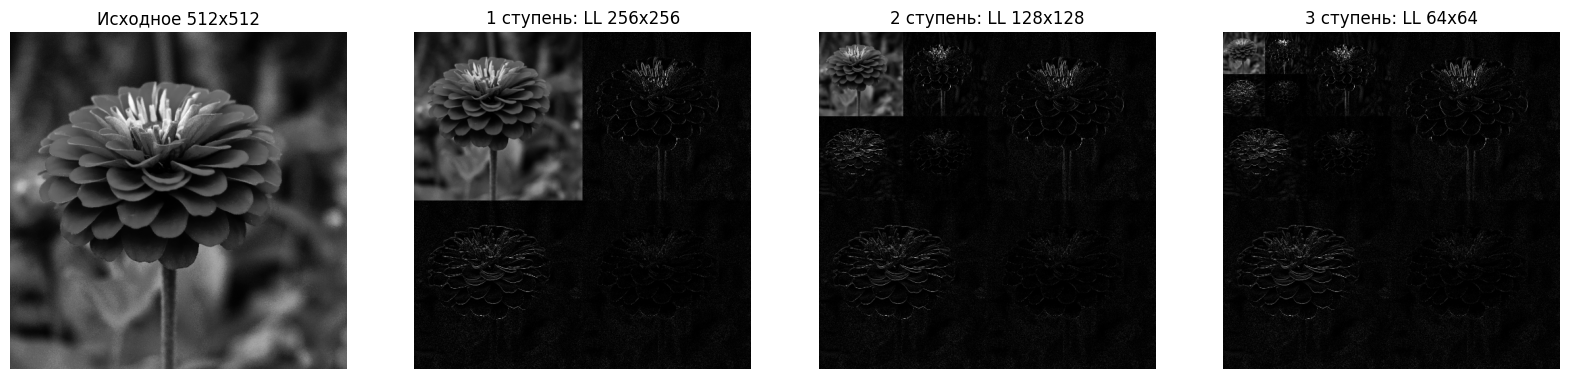

In [12]:
#task1
def haar_2d(image, levels):
    coeffs = image.astype(np.float32).copy()
    for level in range(levels):
        size = coeffs.shape[0] >> level
        block = coeffs[:size, :size]

        averages = (block[:, 0::2] + block[:, 1::2]) / 2
        details = (block[:, 0::2] - block[:, 1::2]) / 2
        block = np.concatenate((averages, details), axis=1)

        averages = (block[0::2, :] + block[1::2, :]) / 2
        details = (block[0::2, :] - block[1::2, :]) / 2
        block = np.concatenate((averages, details), axis=0)

        coeffs[:size, :size] = block
    return coeffs


def ihaar_2d(coeffs, levels):
    result = coeffs.astype(np.float32).copy()
    for level in range(levels - 1, -1, -1):
        size = result.shape[0] >> level
        block = result[:size, :size].copy()
        half = size // 2

        top = block[:half, :]
        bottom = block[half:, :]
        rows = np.empty_like(block)
        rows[0::2, :] = top + bottom
        rows[1::2, :] = top - bottom

        left = rows[:, :half]
        right = rows[:, half:]
        result[:size, :size][:, 0::2] = left + right
        result[:size, :size][:, 1::2] = left - right
    return result


plt.figure(figsize=(20, 5))
plt.subplot(141), plt.imshow(image, cmap='gray')
plt.title('Исходное 512x512'), plt.axis('off')

for level in range(1, 4):
    coeffs = haar_2d(image, level)
    vis = np.clip(np.abs(coeffs) * 5, 0, 255)
    size = image.shape[0] >> level
    vis[:size, :size] = coeffs[:size, :size]

    plt.subplot(1, 4, level + 1)
    plt.imshow(vis, cmap='gray')
    plt.title('{} ступень: LL {}x{}'.format(level, size, size))
    plt.axis('off')
plt.show()


Обнулено: 93.9%   MSE: 21.97


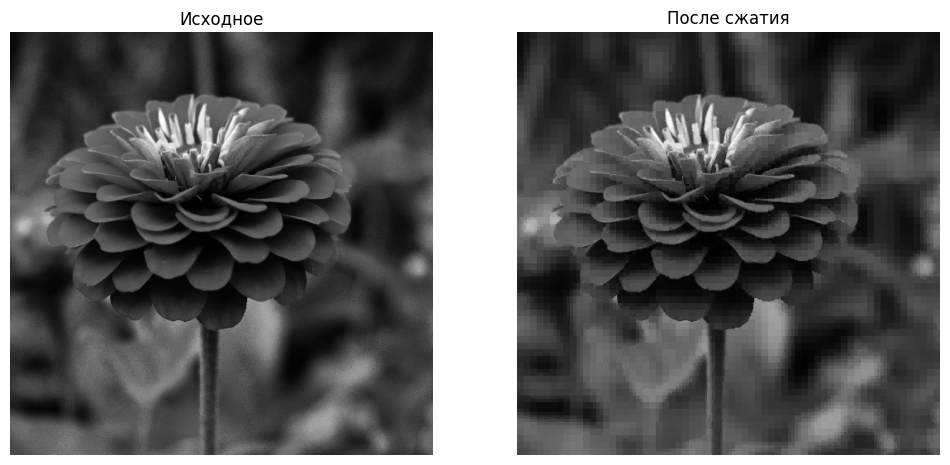

In [16]:
coeffs = haar_2d(image, 3)

compressed = coeffs.copy()
compressed[np.abs(compressed) < 5] = 0
compressed[:64, :64] = coeffs[:64, :64]
restored = np.clip(ihaar_2d(compressed, 3), 0, 255)

print('Обнулено: {:.1f}%   MSE: {:.2f}'.format(np.mean(compressed == 0) * 100, np.mean((restored - image) ** 2)))

plt.figure(figsize=(12, 6))
plt.subplot(121), plt.imshow(image, cmap='gray')
plt.title('Исходное'), plt.axis('off')
plt.subplot(122), plt.imshow(restored, cmap='gray')
plt.title('После сжатия'), plt.axis('off')
plt.show()
